In [3]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
df = sns.load_dataset("taxis")
print(df.head())


               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

In [4]:
print(df.shape)
print(df.columns)
print(df.info())

(6433, 14)
Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str       

In [5]:
print(df.isnull().sum())

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [6]:
print(df.isnull().sum()[df.isnull().sum() > 0])

payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [7]:
df_clean = df.copy()

for col in df_clean.select_dtypes(include="number").columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())
for col in df_clean.select_dtypes(include=["object", "category", "string"]).columns:
    if df_clean[col].isnull().any() and not df_clean[col].mode().empty:
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])
print(df_clean.isnull().sum())


pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [8]:
df_clean = df_clean.dropna(subset=["pickup", "fare"])
df_clean["pickup"] = pd.to_datetime(df_clean["pickup"])
print(df_clean.isnull().sum())


pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


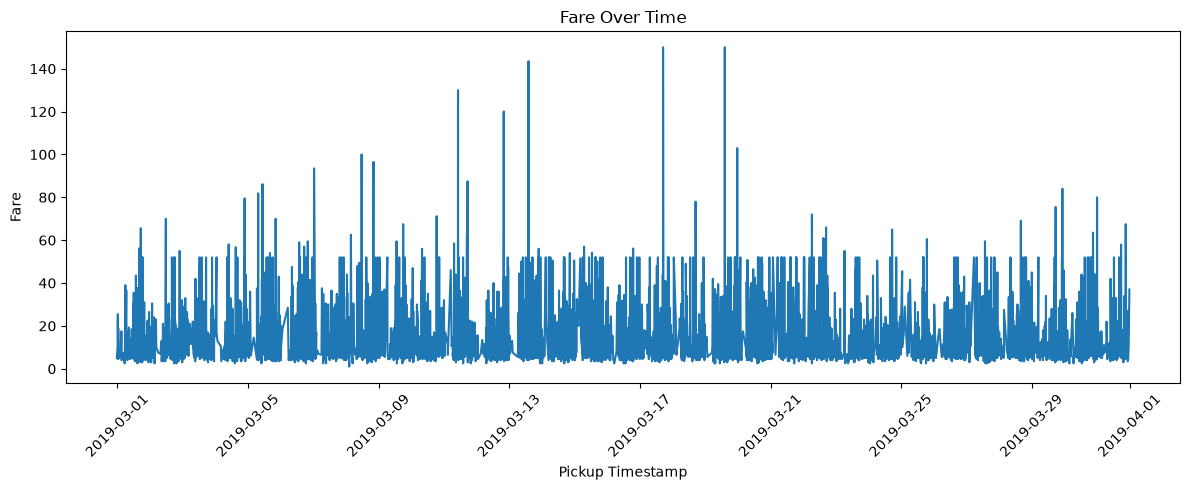

In [54]:
df_line = df_clean.sort_values("pickup")
plt.figure(figsize=(12, 5))
plt.plot(df_line["pickup"], df_line["fare"])
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare")
plt.title("Fare Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

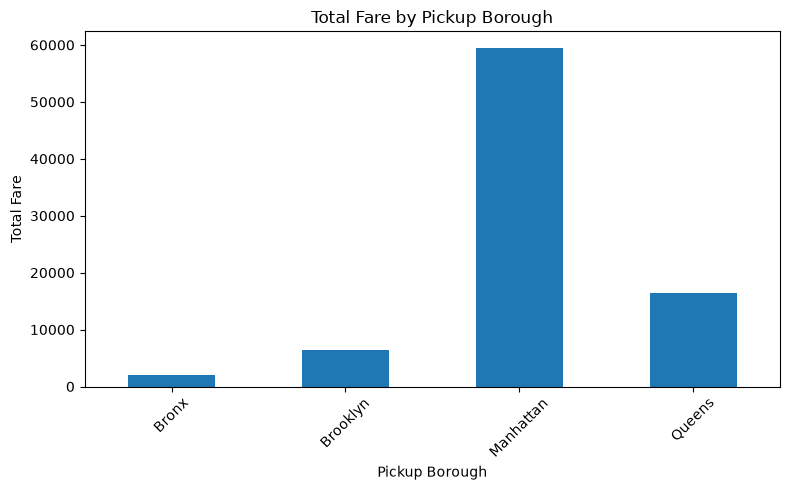

In [55]:
borough_fare = df_clean.groupby("pickup_borough")["fare"].sum()
borough_fare.plot(kind="bar", figsize=(8, 5))
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.title("Total Fare by Pickup Borough")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

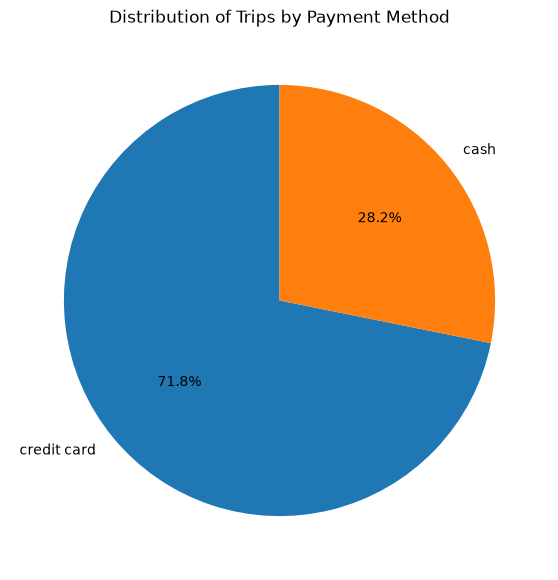

In [56]:
payment_counts = df_clean["payment"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90)
plt.title("Distribution of Trips by Payment Method")
plt.show()


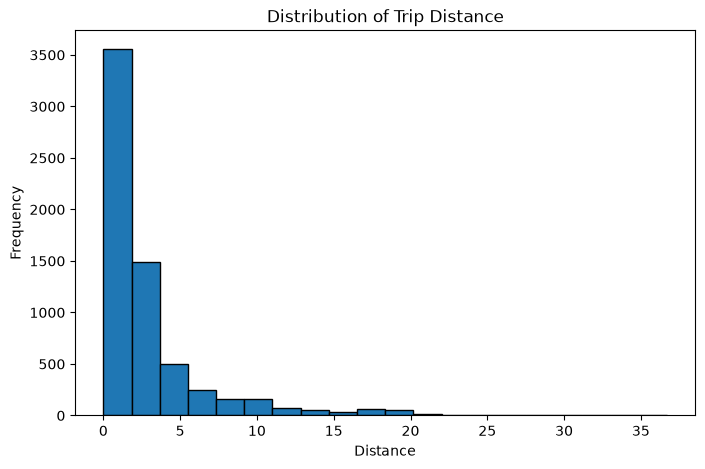

In [57]:
plt.figure(figsize=(8, 5))
plt.hist(df_clean["distance"].dropna(), bins=20, edgecolor="black")
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.title("Distribution of Trip Distance")
plt.show()

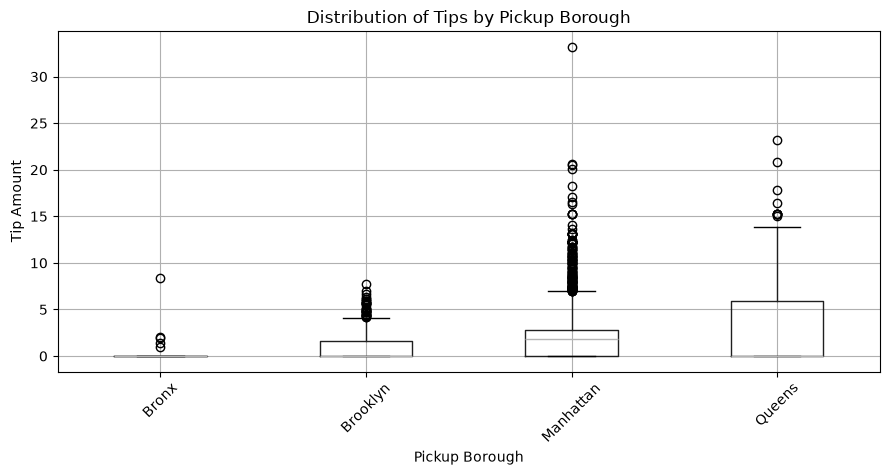

In [58]:
df_clean.boxplot(
    column="tip",
    by="pickup_borough",
    figsize=(9, 5))
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.title("Distribution of Tips by Pickup Borough")
plt.suptitle("")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

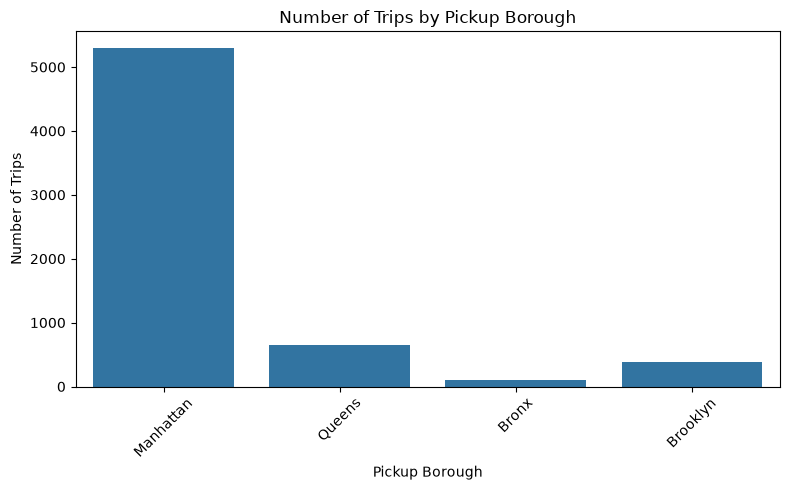

In [59]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x="pickup_borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.title("Number of Trips by Pickup Borough")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

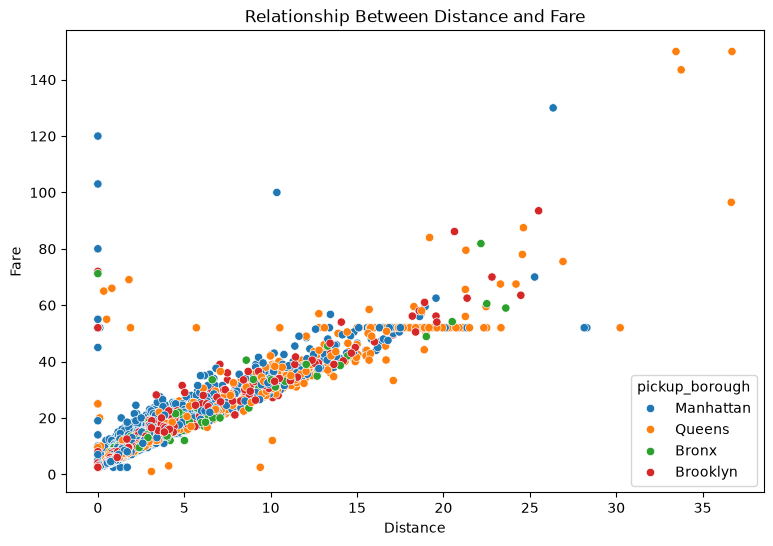

In [60]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_clean,
    x="distance",
    y="fare",
    hue="pickup_borough")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.title("Relationship Between Distance and Fare")
plt.show()

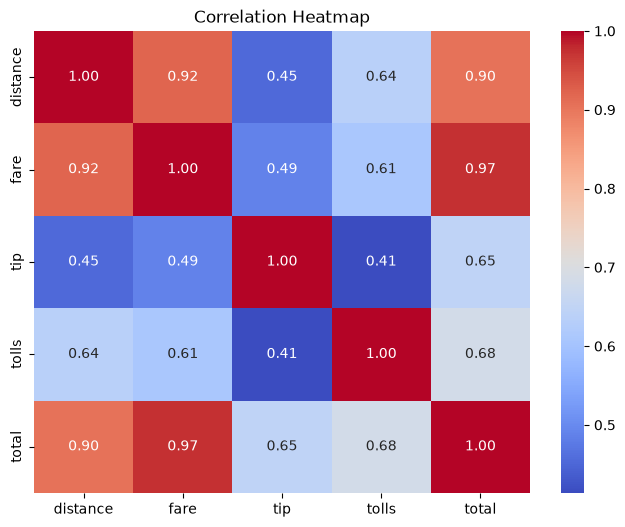

In [61]:
num_data = df_clean[["distance", "fare", "tip", "tolls", "total"]]
correlation = num_data.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

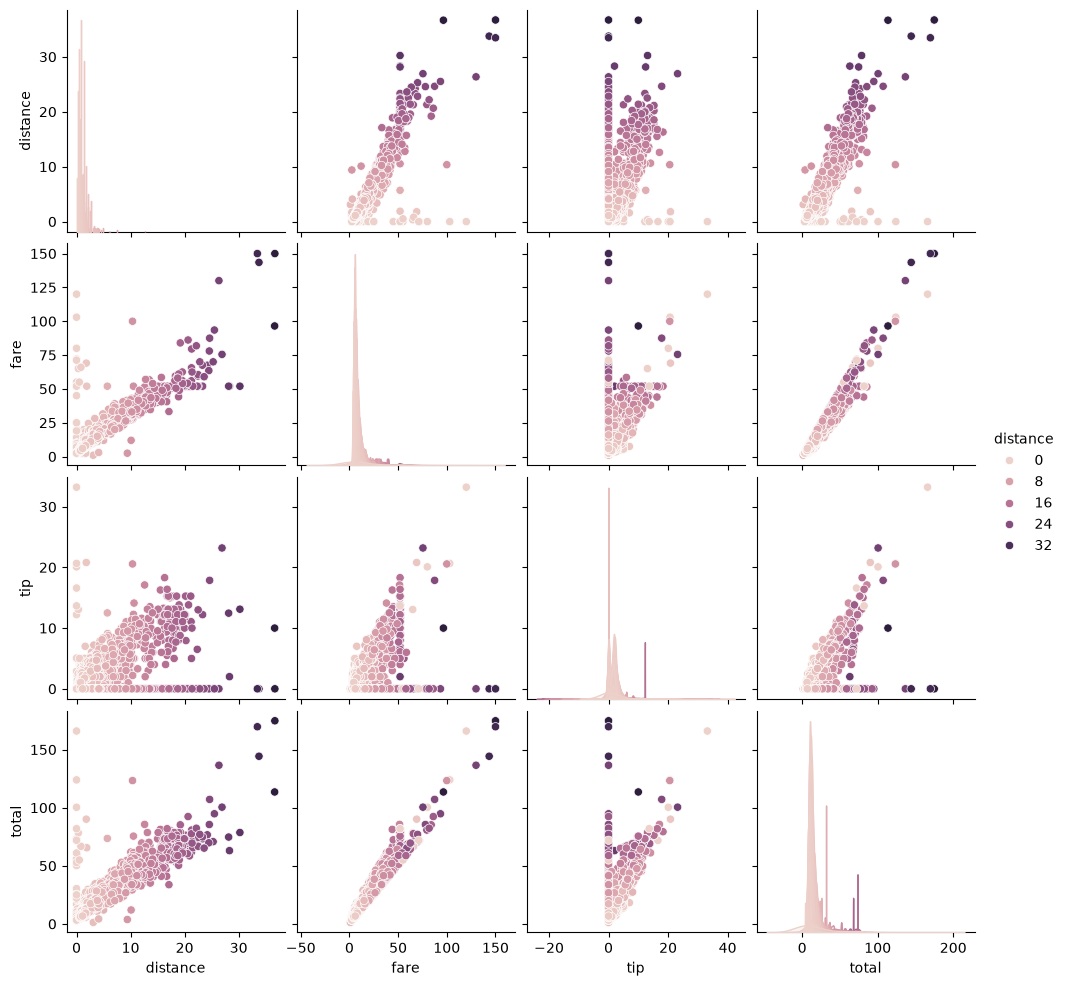

In [9]:
pair_data = df_clean[
    ["distance", "fare", "tip", "total", "pickup_zone"]
].dropna()
sns.pairplot(
    data=pair_data,
    vars=["distance", "fare", "tip", "total"],
    hue="distance")
plt.show()

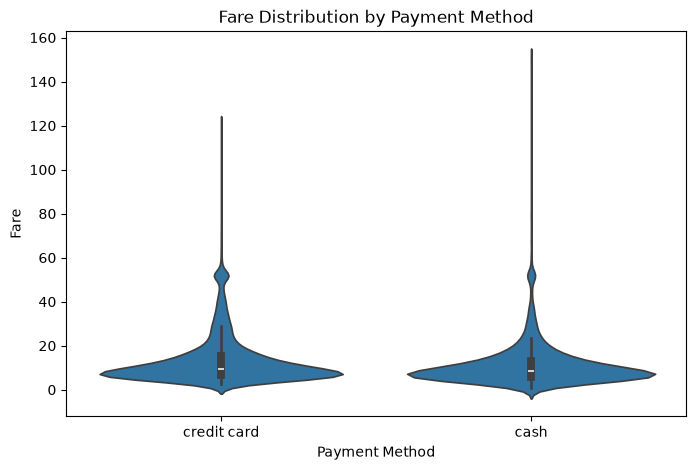

In [65]:
plt.figure(figsize=(8, 5))
sns.violinplot(
    data=df_clean,
    x="payment",
    y="fare")
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.title("Fare Distribution by Payment Method")
plt.show()